[Open in Colab](https://colab.research.google.com/github/nz-gravity/sgvb_psd/blob/main/docs/examples/LVK_example.ipynb)

# LVK example

Use the 128-second off-source H1 strain excerpt in
[Jianan's AR-SGVB example](https://github.com/jianan-joseph-liu/cleared_unisgvb/blob/ee515546a389e935b01d1bb1fac26240a52563b0/estimate_gw150914_psd.py)
(about 4 MB, ending two seconds before GW150914). Following its AR-prewhitening
idea, fit **one AR(1024) baseline** to capture the broad shape and lines; do not
search for the best order. SGVB handles residual whitening and reconstruction
internally, so the reference is applied exactly once. A 1,024-harmonic
residual basis can correct narrow line widths; the AR baseline need not be optimal.

The first 32 seconds train the AR model, the next 64 seconds train SGVB, and
the final 32 seconds are held out. Downsample to 1024 Hz with anti-aliasing,
high-pass at 8 Hz, and analyse 20–400 Hz in four-second normalized Hann blocks.
The target is this processed, window-resolved strain PSD. Set
`DETECTORS=("H1", "L1")` for two cached downloads and a joint spectral-matrix fit.

The cached excerpt contains timestamps/strain, but no data-quality masks.
This is a noise-estimation demonstration rather than a full detector-quality
or astrophysical analysis. The [GWOSC event record](https://gwosc.org/eventapi/json/GWTC-1-confident/GW150914/v3/)
identifies the event time and original public strain products.


## Setup

In [1]:
# Colab installs the package; local runs use the project environment.
import subprocess
import sys

try:
    import google.colab
except ImportError:
    print("Using the local SGVB environment. See the repository's uv setup instructions.")
else:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "jax[cpu]==0.6.2", "numpyro==0.19.0",
        "sgvb_psd[examples] @ git+https://github.com/nz-gravity/sgvb_psd.git@main",
    ])


Using the local SGVB environment. See the repository's uv setup instructions.


In [2]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found.*")
from pathlib import Path
from time import perf_counter
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from sgvb_psd.psd_estimator import PSDEstimator
from sgvb_psd.ar_reference import fit_ar_reference
import jax

%matplotlib inline
plt.rcParams.update({"font.family": "sans-serif", "font.size": 11,
    "axes.labelsize": 11, "axes.titlesize": 12, "legend.fontsize": 8,
    "figure.dpi": 110, "text.usetex": False})
print("JAX", jax.__version__, "devices:", jax.devices())
# Fixed budgets: no order or learning-rate search on the validation segment.
BUDGET = dict(N_theta=1024, degree_fluctuate=1024, ntrain_map=8000, n_elbo_maximisation_steps=2000,
              optimize_mean=True, elbo_samples=4, vi_learning_rate=.005,
              N_samples=128, seed=7)


21:31:15|SGVB-PSD|INFO| No GPU detected. Running on CPU.
JAX 0.6.2 devices: [CpuDevice(id=0)]


## Separate training, analysis and validation blocks

In [3]:
from urllib.request import urlopen
from hashlib import sha256
import shutil

DETECTORS = ("H1",)
SOURCE_REVISION = "ee515546a389e935b01d1bb1fac26240a52563b0"
CHECKSUMS = {
    "H1": "634ddb374cb1cfab487a6364007c110540d37e1fea4676800a51a7fdf874c106",
    "L1": "1f00a2e68fa135affbea8835ab3e116997c8fb3e7b844728432b8869ebb9cbe5",
}
CACHE = Path("data"); CACHE.mkdir(exist_ok=True)
channels, epochs = [], []
for detector in DETECTORS:
    filename = f"{detector}_1126259332400_1126259460400.npz"
    path = CACHE/filename
    if not path.exists():
        url = f"https://raw.githubusercontent.com/jianan-joseph-liu/cleared_unisgvb/{SOURCE_REVISION}/data_cache/{filename}"
        temporary = path.with_suffix(".part")
        with urlopen(url, timeout=60) as response, temporary.open("wb") as destination:
            shutil.copyfileobj(response, destination)
        temporary.replace(path)
    assert sha256(path.read_bytes()).hexdigest() == CHECKSUMS[detector], "Cached strain differs from the fixed input"
    with np.load(path, allow_pickle=False) as saved:
        channels.append(np.asarray(saved["values"], dtype=float))
        epochs.append(float(saved["epoch"]))
        assert np.isclose(float(saved["dt"]), 1/4096, rtol=0, atol=1e-12)
assert np.allclose(epochs, epochs[0], rtol=0, atol=1e-6)
raw = np.column_stack(channels)
assert raw.shape == (524288, len(DETECTORS)) and np.isfinite(raw).all()
assert abs(epochs[0]+128-(1126259462.4-2)) < .01
fs = 1024.
BLOCK_SAMPLES = 4096
reduced = signal.resample_poly(raw, up=1, down=4, axis=0)
highpass = signal.butter(4, 8., btype="highpass", fs=fs, output="sos")
reduced = signal.sosfiltfilt(highpass, reduced, axis=0)
def taper_blocks(values, block_samples):
    """Center each block and apply a unit-mean-square periodic Hann window."""
    blocks = values.reshape(-1, block_samples, values.shape[1])
    window = signal.windows.hann(block_samples, sym=False)
    window /= np.sqrt(np.mean(window**2))
    nbw = block_samples*np.sum(window**2)/np.sum(window)**2
    result = ((blocks-blocks.mean(axis=1, keepdims=True))*window[None, :, None])
    return result.reshape(values.shape), nbw

training, nbw = taper_blocks(reduced[:32*1024], BLOCK_SAMPLES)
data, _ = taper_blocks(reduced[32*1024:96*1024], BLOCK_SAMPLES)
heldout, _ = taper_blocks(reduced[96*1024:], BLOCK_SAMPLES)
print("Training / analysis / held-out samples:", training.shape, data.shape, heldout.shape)


Training / analysis / held-out samples: (32768, 1) (65536, 1) (32768, 1)


## A fast initial AR fit

Fixed-order Yule–Walker/Levinson–Durbin fitting follows the baseline idea in Jianan’s example.
The reference is a full matrix with a diagonal entry per detector; SGVB retains network cross-spectra.
The input convention here is two-sided and the windows have unit energy, so no manual
whitening, recolouring, window-energy division or doubling is applied.

In [4]:
AR_ORDER = 1024  # Fixed before fitting; increase deliberately for another analysis.
start = perf_counter()
reference = fit_ar_reference(training, fs, order=AR_ORDER)
ar_seconds = perf_counter()-start
print(f"AR({reference.order}) baseline: {ar_seconds:.3f} s for {reference.n_channels} channel(s); no order search")


AR(1024) baseline: 0.005 s for 1 channel(s); no order search


## Fit the residual spectral matrix

In [5]:
from sgvb_psd.inference import CoarseGrainConfig
# Native bins are affordable here. The optional pilot is frozen before fitting.
USE_COARSE_GRAINING = False
coarse = (CoarseGrainConfig(max_bin_width=8, pilot_window=3, tolerance=.1)
          if USE_COARSE_GRAINING else None)
start = perf_counter()
estimator = PSDEstimator(data, fs=fs, reference_psd=reference,
    parallel_rows=True, coarse_grain=coarse, nchunks=len(data)//BLOCK_SAMPLES, Nbw=nbw,
    fmin_for_analysis=20., fmax_for_analysis=400., **BUDGET)
_ = estimator.run(lr=.001)
fit_seconds = perf_counter()-start
assert np.isfinite(estimator.pointwise_ci).all()
print(f"{len(data)} samples × {data.shape[1]} channels; {estimator.nchunks} blocks; fit + compilation + draws {fit_seconds:.2f} s")
print("Independent vmapped Cholesky-row dimensions:", estimator.inference_runner.row_dimensions)

print("Native / likelihood frequencies:", len(estimator.freq), len(estimator.model.data.likelihood_freq))

21:31:15|SGVB-PSD|INFO| Dividing data (65536, 1) into (16, 4096, 1) chunks
21:31:15|SGVB-PSD|INFO| Reducing the number of frequencies to be analyzed from 2048 to 400.0...
21:31:15|SGVB-PSD|INFO| Final PSD will be of shape: 1520 x 1 x 1
21:31:15|SGVB-PSD|WARNING| Input data not standardised!
21:31:15|SGVB-PSD|INFO| Using provided learning rate: 0.001
21:31:15|SGVB-PSD|INFO| Training model
21:31:19|SGVB-PSD|INFO| Model trained in 3.24s
21:31:19|SGVB-PSD|INFO| Computing posterior PSDs
65536 samples × 1 channels; 16 blocks; fit + compilation + draws 7.48 s
Independent vmapped Cholesky-row dimensions: (2051,)
Native / likelihood frequencies: 1520 1520


## Spectra and held-out checks

Bands are 90% variational intervals conditional on the fixed reference.
Coherence curves are formed after the same nine-bin spectral-matrix smoothing
(2.25 Hz), including each posterior draw, so their frequency resolutions match.

In [6]:
from scipy.ndimage import uniform_filter1d

COLORS = dict(fit="#1764a0", reference="#ae7c00", heldout="#303030")

def spectral_average(values, nperseg, fs, frequencies):
    # Values have already been centered/windowed: do not window a second time.
    blocks = values.reshape(-1, nperseg, values.shape[1])
    transformed = np.fft.rfft(blocks, axis=1)/np.sqrt(nperseg*fs)
    full_frequency = np.fft.rfftfreq(nperseg, 1/fs)
    indices = np.searchsorted(full_frequency, frequencies)
    np.testing.assert_allclose(full_frequency[indices], frequencies, atol=1e-12)
    transformed = transformed[:, indices]
    return np.einsum("bfi,bfj->fij", transformed, transformed.conj())/len(blocks)

def show_spectra(estimator, data, heldout, labels, reference):
    frequencies = estimator.freq
    empirical = spectral_average(data, estimator.nt_per_chunk, estimator.fs, frequencies)
    validation = spectral_average(heldout, estimator.nt_per_chunk, estimator.fs, frequencies)
    baseline = reference(frequencies)
    fig, axes = plt.subplots(len(labels), 1, figsize=(7.2, 2.9*len(labels)), squeeze=False)
    for j, ax in enumerate(axes[:, 0]):
        q = estimator.pointwise_ci[:, :, j, j].real
        ax.loglog(frequencies, empirical[:, j, j].real, color=".65", lw=.7, label="Analysis block average")
        ax.loglog(frequencies, baseline[:, j, j].real, ":", color=COLORS["reference"], lw=1.1, label="Fixed AR/VAR reference")
        ax.fill_between(frequencies, q[0], q[2], color=COLORS["fit"], alpha=.2)
        ax.loglog(frequencies, q[1], color=COLORS["fit"], lw=1.1, label="SGVB median; 90% VI band")
        ax.set(title=labels[j], xlabel="Frequency [Hz]", ylabel="Two-sided PSD [strain²/Hz]")
        ax.grid(alpha=.2); ax.legend(fontsize=8)
    fig.tight_layout(); plt.show()
    return empirical, validation, baseline

def smooth_matrix(spectrum, width=9, axis=0):
    return (uniform_filter1d(spectrum.real, width, axis=axis, mode="nearest")
            + 1j*uniform_filter1d(spectrum.imag, width, axis=axis, mode="nearest"))

def show_coherence(estimator, empirical, validation, baseline, labels):
    pairs = [(i, j) for j in range(len(labels)) for i in range(j)]
    if not pairs: return
    # Match the same 9-bin matrix smoothing for every curve and posterior draw.
    draws = smooth_matrix(estimator.psd_all, axis=1)
    matrices = [smooth_matrix(s) for s in (empirical, validation, baseline)]
    fig, axes = plt.subplots(len(pairs), 1, figsize=(7.2, 2.5*len(pairs)), squeeze=False)
    for ax, (i, j) in zip(axes[:, 0], pairs):
        coh = abs(draws[:, :, i, j])**2/(draws[:, :, i, i].real*draws[:, :, j, j].real)
        q = np.quantile(coh, [.05, .5, .95], axis=0)
        ax.fill_between(estimator.freq, q[0], q[2], color=COLORS["fit"], alpha=.2)
        ax.plot(estimator.freq, q[1], color=COLORS["fit"], label="SGVB; 90% VI band")
        for matrix, style, color, label in zip(matrices, ["-", "--", ":"],
                [".7", COLORS["heldout"], COLORS["reference"]],
                ["Analysis block average", "Held-out block average", "Fixed reference"]):
            value = abs(matrix[:, i, j])**2/(matrix[:, i, i].real*matrix[:, j, j].real)
            ax.plot(estimator.freq, value, style, color=color, lw=.9, label=label)
        ax.set(title=f"{labels[i]}–{labels[j]}", xlabel="Frequency [Hz]",
               ylabel="Smoothed coherence", ylim=(0, 1))
        ax.grid(alpha=.2); ax.legend(fontsize=8)
    fig.tight_layout(); plt.show()

def check_fit(estimator, validation, baseline, labels):
    # Convex averaging preserves SPD; elementwise matrix quantiles need not.
    posterior_mean = estimator.psd_all.mean(axis=0)*estimator.psd_scaling**2
    def whittle_score(spectrum):
        # Normalize both matrices first to avoid squaring tiny strain units.
        units = np.trace(validation, axis1=-2, axis2=-1).real.mean()/len(labels)
        normalized = spectrum/units
        _, logdet = np.linalg.slogdet(normalized)
        trace = np.trace(np.linalg.solve(normalized, validation/units), axis1=-2, axis2=-1).real
        return np.mean(logdet+trace)
    delta = whittle_score(posterior_mean)-whittle_score(baseline)
    print(f"Held-out plug-in Whittle score: SGVB − reference = {delta:.3f} nats/vector (lower is better)")
    print("This is predictive agreement on one segment, not a coverage/calibration test.")
    for j, label in enumerate(labels):
        ratio = (posterior_mean[:, j, j].real.sum()/validation[:, j, j].real.sum())
        print(f"{label}: fitted/held-out integrated band power = {ratio:.3f}")
    lp = np.asarray(estimator.inference_runner.row_lp)
    losses = np.asarray(estimator.inference_runner.row_kdl_losses)
    assert np.isfinite(lp).all() and np.isfinite(losses).all()
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.8))
    for j, label in enumerate(labels):
        axes[0].plot(lp[j]-lp[j, 0], lw=.8, label=label)
        smoothed = np.convolve(losses[j], np.ones(50)/50, mode="valid")
        steps = np.arange(len(smoothed))+49
        tail = steps >= 500
        axes[1].plot(steps[tail], smoothed[tail]-smoothed[tail][0], lw=.8, label=label)
    axes[0].set(xlabel="MAP iteration", ylabel="Log-posterior gain")
    axes[1].set(xlabel="VI iteration", ylabel="VI tail: negative ELBO change (50-step mean)")
    for ax in axes: ax.grid(alpha=.2); ax.legend(fontsize=8)
    fig.tight_layout(); plt.show()


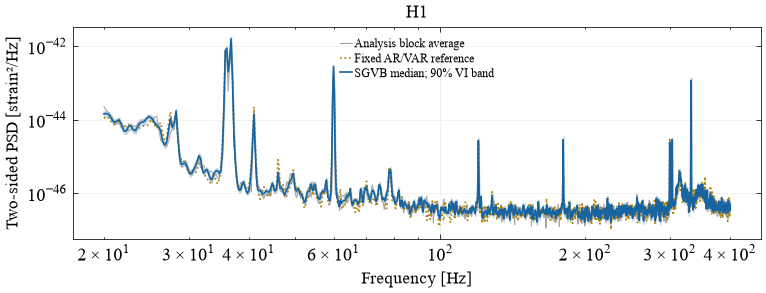

In [7]:
labels = list(DETECTORS)
empirical, validation, baseline = show_spectra(estimator, data, heldout, labels, reference)
show_coherence(estimator, empirical, validation, baseline, labels)

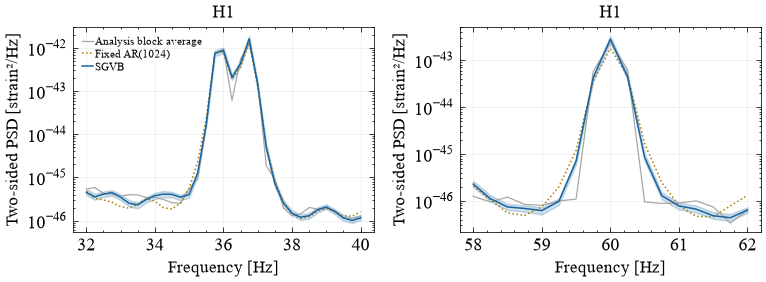

In [8]:
# Check that the fast initial baseline retains narrow lines, rather than
# judging it only by a broad log-frequency view. Zooms are fixed in advance.
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.8))
for ax, bounds in zip(axes, [(32., 40.), (58., 62.)]):
    keep = (estimator.freq >= bounds[0]) & (estimator.freq <= bounds[1])
    f = estimator.freq[keep]
    q = estimator.pointwise_ci[:, keep, 0, 0].real
    ax.semilogy(f, empirical[keep, 0, 0].real, color=".65", lw=.8, label="Analysis block average")
    ax.semilogy(f, baseline[keep, 0, 0].real, ":", color=COLORS["reference"], label=f"Fixed AR({AR_ORDER})")
    ax.fill_between(f, q[0], q[2], color=COLORS["fit"], alpha=.2)
    ax.semilogy(f, q[1], color=COLORS["fit"], label="SGVB")
    ax.set(title=DETECTORS[0], xlabel="Frequency [Hz]", ylabel="Two-sided PSD [strain²/Hz]")
    ax.grid(alpha=.2)
axes[0].legend(fontsize=7); fig.tight_layout(); plt.show()


## Predictive agreement and optimizer traces

Held-out plug-in Whittle score: SGVB − reference = -0.032 nats/vector (lower is better)
This is predictive agreement on one segment, not a coverage/calibration test.
H1: fitted/held-out integrated band power = 1.101


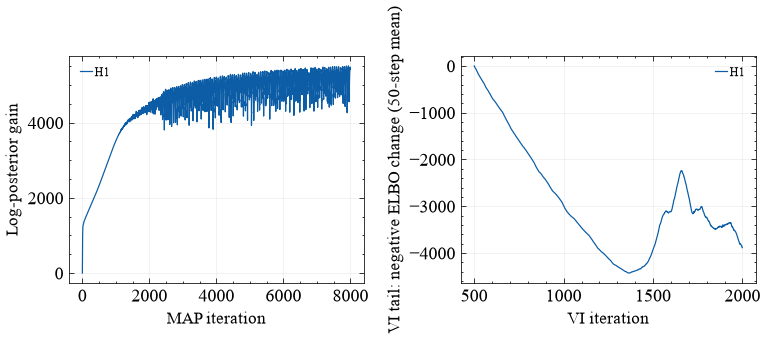

In [9]:
check_fit(estimator, validation, baseline, labels)

## What this fit demonstrates

The AR/VAR model is a cheap **fixed initial reference**. SGVB learns a smooth
residual spectral matrix and reconstructs the physical spectrum. AR order is
fixed in advance; no order search or TensorFlow installation is needed.
The independent modified-Cholesky rows are still fitted together with JAX `vmap`.

The Hann windows have unit mean-square, so no extra window-energy correction
or factor of two is applied to the returned two-sided PSD. The target is the
window-resolved spectrum of the processed data. `Nbw=1.5` is an approximate
Hann bandwidth correction for the Whittle likelihood, not an exact model of
inter-frequency dependence.

The shaded bands are 90% variational intervals **conditional on the fitted
reference**. They exclude uncertainty in AR coefficients and do not establish
calibrated coverage. Trainable variational means and four ELBO particles reduce
dependence on the final MAP iterate; inspect the displayed optimization traces
instead of treating the finite budget as a convergence certificate.
The VI panel shows the tail after iteration 500 so the large initial transient
does not hide late optimization behaviour. Held-out
scores use the posterior mean spectral matrix as a plug-in prediction; the
held-out blocks are excluded from AR and SGVB parameter fitting. This single
split is an illustrative diagnostic, not a blinded model-selection study.

The larger residual basis uses a smaller VI learning rate (0.005) and 8,000
MAP steps. The native frequency grid is the default; toggle the explicit
coarse-graining option for a separate approximation/cost comparison.
